In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

from pathlib import Path

In [2]:
project_root = Path.cwd()

if not (project_root / "data").is_dir():
    project_root = project_root.parent

listings_path = project_root / "data" / "detailed_listings.csv"

listings = pd.read_csv(listings_path)

In [63]:
charts_dir = project_root / "outputs" / "charts"
charts_dir.mkdir(parents=True, exist_ok=True)

In [3]:
listings.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,360,https://www.airbnb.com/rooms/360,20260630053644,2026-06-30,city scrape,Denver’s Peaceful Oasis for Travel Nurses & No...,Enjoy the famous Colorado weather and unplug i...,NaN,https://a0.muscache.com/pictures/monet/Select-...,666,...,4.99,4.98,4.90,2017-BFN-0002177,NaN,1,1,0,0,1.94
1,364,https://www.airbnb.com/rooms/364,20260630053644,2026-07-02,previous scrape,Lodo / RiNo LOFT via airport train,"Modern 1,000 square foot loft in the heart of ...",NaN,https://a0.muscache.com/pictures/11766413/a2c5...,783,...,4.96,4.65,4.71,NaN,NaN,1,1,0,0,0.42
2,592,https://www.airbnb.com/rooms/592,20260630053644,2026-06-30,city scrape,private,This room is in the basement. It does not hav...,NaN,https://a0.muscache.com/pictures/ba522ff9-84c9...,933,...,4.96,4.84,4.88,2021-BFN-0000578,NaN,1,0,1,0,1.05
3,686,https://www.airbnb.com/rooms/686,20260630053644,2026-06-30,city scrape,Alexandra's Queen Bed Room Long-term Rental Only,Thanks for visiting my Queen Bed Room for LONG...,NaN,https://a0.muscache.com/pictures/108112/e6d5d3...,990,...,4.91,4.87,4.82,NaN,NaN,1,0,1,0,1.16
4,1940,https://www.airbnb.com/rooms/1940,20260630053644,2026-06-30,city scrape,"Baker Studio Pet-friendly, Walkable, Patio",Private studio retreat in a charming historic ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,2150,...,4.99,4.90,4.90,2018-BFN-0002596,NaN,2,2,0,0,2.42


In [4]:
listings.shape

(4939, 90)

In [5]:
listings.columns.tolist()

['id',
 'listing_url',
 'scrape_id',
 'last_scraped',
 'source',
 'name',
 'description',
 'neighborhood_overview',
 'picture_url',
 'host_id',
 'host_url',
 'host_profile_id',
 'host_profile_url',
 'host_name',
 'host_since',
 'hosts_time_as_user_years',
 'hosts_time_as_user_months',
 'hosts_time_as_host_years',
 'hosts_time_as_host_months',
 'host_location',
 'host_about',
 'host_response_time',
 'host_response_rate',
 'host_acceptance_rate',
 'host_is_superhost',
 'host_thumbnail_url',
 'host_picture_url',
 'host_neighbourhood',
 'host_listings_count',
 'host_total_listings_count',
 'host_verifications',
 'host_has_profile_pic',
 'host_identity_verified',
 'neighbourhood',
 'neighbourhood_cleansed',
 'neighbourhood_group_cleansed',
 'latitude',
 'longitude',
 'property_type',
 'room_type',
 'accommodates',
 'bathrooms',
 'bathrooms_text',
 'bedrooms',
 'beds',
 'amenities',
 'price',
 'price_quote_checkin_date',
 'price_quote_checkout_date',
 'price_quote_total_price',
 'price_quote

In [6]:
listings.dtypes

id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 90, dtype: object

In [7]:
# How many listings are in the dataset?

len(listings)

4939

In [8]:
# How many unique neighborhoods are represented in neighbourhood_cleansed?

print(listings['neighbourhood_cleansed'].nunique())

77


In [9]:
# How many listings belong to each room_type?

listings.groupby("room_type")["id"].count()

room_type
Entire home/apt    4233
Hotel room           23
Private room        631
Shared room          52
Name: id, dtype: int64

In [10]:
listings["room_type"].value_counts()

room_type
Entire home/apt    4233
Private room        631
Shared room          52
Hotel room           23
Name: count, dtype: int64

In [11]:
import duckdb

con = duckdb.connect()

In [12]:
con.execute("SELECT 1 + 1 AS result").df()

,result
0,2


In [13]:
from pathlib import Path

print(Path.cwd())

/Users/andyzhang/Documents/Denver-Airbnb-Analysis/notebooks


In [14]:
print(listings_path)
print(listings_path.exists())

/Users/andyzhang/Documents/Denver-Airbnb-Analysis/data/detailed_listings.csv
True


In [15]:
con.execute("""
    SELECT
        COUNT(*) AS total_listings,
        COUNT(DISTINCT neighbourhood_cleansed) AS total_neighborhoods
    FROM read_csv_auto(?)
""", [str(listings_path)]).df()

,total_listings,total_neighborhoods
0,4939,77


In [16]:
csv_files = {
    "raw_listings": "detailed_listings.csv",
    "raw_calendar": "detailed_calendar.csv",
    "raw_reviews": "detailed_reviews.csv"
}

for view_name, filename in csv_files.items():
    file_path = project_root / "data" / filename

    con.execute(
        f"CREATE OR REPLACE VIEW {view_name} AS "
        f"SELECT * FROM read_csv_auto('{file_path.as_posix()}')"
    )

In [17]:
con.execute("""
    SELECT
        (SELECT COUNT(*) FROM raw_listings) AS listing_count,
        (SELECT COUNT(*) FROM raw_calendar) AS calendar_count,
        (SELECT COUNT(*) FROM raw_reviews) AS review_count
""").df()

,listing_count,calendar_count,review_count
0,4939,1806385,354741


In [18]:
cleaning_sql_path = project_root / "sql" / "01_cleaning.sql"

cleaning_sql = cleaning_sql_path.read_text(encoding="utf-8")

con.execute(cleaning_sql)

In [19]:
con.execute("""
    SELECT table_name
    FROM information_schema.views
    WHERE table_name LIKE 'cleaned_%'
    ORDER BY table_name
""").df()

,table_name
0,cleaned_calendar
1,cleaned_listings
2,cleaned_reviews


In [20]:
con.execute("""
    SELECT
        (SELECT COUNT(*) FROM cleaned_listings) AS listings,
        (SELECT COUNT(*) FROM cleaned_calendar) AS calendar,
        (SELECT COUNT(*) FROM cleaned_reviews) AS reviews
""").df()

,listings,calendar,reviews
0,4939,1802735,354646


In [21]:
con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT id) AS unique_listings,
        COUNT(*) - COUNT(DISTINCT id) AS duplicate_rows
    FROM cleaned_listings
""").df()

,total_rows,unique_listings,duplicate_rows
0,4939,4939,0


In [22]:
con.execute("""
    SELECT
        id,
        neighbourhood_cleansed,
        room_type,
        cleaned_price,
        price_status,
        host_scale,
        property_category,
        amenity_count,
        stay_policy,
        listing_activity_status
    FROM cleaned_listings
    LIMIT 5
""").df()

,id,neighbourhood_cleansed,room_type,cleaned_price,price_status,host_scale,property_category,amenity_count,stay_policy,listing_activity_status
0,1609550371032300730,Montbello,Entire home/apt,325.5,Typical range,Small multi-listing host,House/Home,48,Short stay,Recently Reviewed
1,1610255566922845326,West Highland,Entire home/apt,249.0,Typical range,Single-listing host,House/Home,15,Short stay,Recently Reviewed
2,1611181276254799867,Union Station,Entire home/apt,360.1,Typical range,Small multi-listing host,House/Home,11,Monthly stay,Never Reviewed
3,1611820732712003794,CBD,Entire home/apt,NaN,Missing price,Single-listing host,Apartment/Rental Unit,45,Monthly stay,Never Reviewed
4,1612605935579140935,Speer,Entire home/apt,64.9,Typical range,Single-listing host,Apartment/Rental Unit,38,Monthly stay,Never Reviewed


In [23]:
cleaned_listings_df = con.execute("""
    SELECT *
    FROM cleaned_listings
""").df()

cleaned_listings_df.shape

(4939, 55)

In [24]:
cleaned_listings_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4939 entries, 0 to 4938
Data columns (total 55 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              4939 non-null   int64         
 1   last_scraped                    4939 non-null   datetime64[us]
 2   source                          4939 non-null   str           
 3   name                            4939 non-null   str           
 4   host_id                         4939 non-null   int64         
 5   host_name                       4939 non-null   str           
 6   host_location                   4171 non-null   str           
 7   host_location_category          4939 non-null   str           
 8   host_is_superhost               4939 non-null   bool          
 9   host_listings_count             4939 non-null   int64         
 10  calculated_host_listings_count  4939 non-null   int64         
 11  host_identity_v

In [25]:
comparable_df = cleaned_listings_df[
    (cleaned_listings_df["room_type"] == "Entire home/apt")
    & (cleaned_listings_df["stay_policy"] == "Short stay")
    & (cleaned_listings_df["bedrooms"].between(1, 3))
].copy()

comparable_df 

,id,last_scraped,source,name,host_id,host_name,host_location,host_location_category,host_is_superhost,host_listings_count,...,number_of_reviews_l30d,number_of_reviews_ly,listing_activity_status,review_scores_rating,review_scores_accuracy,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month,price_status
2,854963237650793916,2026-06-30,city scrape,Cozy Spring Getaway in Denver w/Fast Wifi,109534927,Katherine,"Denver, CO",Denver,True,6,...,1,6,Recently Reviewed,4.97,5.00,4.94,4.81,4.90,0.81,Typical range
3,855142734203516176,2026-06-30,city scrape,Modern Townhome | Close to DU | Walk to Wash Park,506476621,Lisa,"Denver, CO",Denver,True,1,...,1,7,Recently Reviewed,4.97,4.97,5.00,4.94,4.91,0.90,High price outlier
4,855327275561281832,2026-06-30,city scrape,Conveniently located in the Heart of LoHi,125178529,Jennifer,"Waimea, HI",Other US State,True,1,...,2,39,Recently Reviewed,4.98,4.99,4.99,5.00,4.92,2.81,High price outlier
5,855947490639190321,2026-06-30,city scrape,The Penn Pad,29181761,Stephanie,"Denver, CO",Denver,True,2,...,5,53,Recently Reviewed,4.98,4.95,5.00,4.88,4.93,4.25,Typical range
6,856533921477060579,2026-06-30,city scrape,2 Bd MidMod Inspired Luxury Guesthouse-Sloans ...,117465438,Stephanie,"Denver, CO",Denver,True,1,...,5,61,Recently Reviewed,5.00,5.00,5.00,4.98,4.96,5.21,Typical range
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4917,808113326309550237,2026-06-30,city scrape,Modern Studio in New Townhouse,5804853,Natalie,"Denver, CO",Denver,True,1,...,5,28,Recently Reviewed,4.93,4.88,4.95,4.85,4.84,4.14,Typical range
4919,851549860123322974,2026-06-30,city scrape,Location! Location! Location! Downtown Denver ...,11019055,Cyndi,"Denver, CO",Denver,True,1,...,3,21,Recently Reviewed,4.99,5.00,5.00,4.98,4.88,2.12,Typical range
4923,853033461610377899,2026-06-30,city scrape,Historic brick bungalow,121073099,Liia,"Denver, CO",Denver,True,1,...,2,22,Recently Reviewed,4.98,4.95,4.96,4.95,4.91,1.73,Typical range
4924,853085938381128350,2026-06-30,city scrape,Prime Location Retreat with Hot Tub and BBQ,9834932,AirSimplicity,"Denver, CO",Denver,True,81,...,2,43,Recently Reviewed,4.84,4.81,4.92,4.84,4.64,2.86,Typical range


In [26]:
comparable_df = cleaned_listings_df[
    (cleaned_listings_df["room_type"] == "Entire home/apt") 
    & (cleaned_listings_df["stay_policy"] == "Short stay") 
    & (cleaned_listings_df["bedrooms"].between(1, 3))
    & (cleaned_listings_df["price_status"] == "Typical range")
    ].copy()

neighborhood_medians = comparable_df.groupby("neighbourhood_cleansed")["cleaned_price"].median().sort_values(ascending=False)

neighborhood_medians.head(10)

neighbourhood_cleansed
Auraria               495.900
Marston               450.290
Cherry Creek          426.000
University Park       378.500
Union Station         376.210
University Hills      374.000
Jefferson Park        367.665
Hampden               356.500
North Capitol Hill    349.000
Highland              339.000
Name: cleaned_price, dtype: float64

In [27]:
comparable_df = cleaned_listings_df[
    (cleaned_listings_df["room_type"] == "Entire home/apt") 
    & (cleaned_listings_df["stay_policy"] == "Short stay") 
    & (cleaned_listings_df["bedrooms"].between(1, 3))
    & (cleaned_listings_df["price_status"] == "Typical range")
    ].copy()

neighborhood_medians = comparable_df.groupby("neighbourhood_cleansed").agg(
    listing_count=("id", "count"),
    median_price=("cleaned_price", "median")
)

neighborhood_medians.sort_values("median_price", ascending=False).head(10)

,listing_count,median_price
neighbourhood_cleansed,,
Auraria,1,495.900
Marston,1,450.290
Cherry Creek,21,426.000
University Park,6,378.500
Union Station,57,376.210
University Hills,7,374.000
Jefferson Park,36,367.665
Hampden,6,356.500
North Capitol Hill,11,349.000


In [28]:
chart_data = neighborhood_medians[
    neighborhood_medians["listing_count"] >= 10
].sort_values("median_price", ascending=False).head(10)

chart_data

,listing_count,median_price
neighbourhood_cleansed,,
Cherry Creek,21,426.000
Union Station,57,376.210
Jefferson Park,36,367.665
North Capitol Hill,11,349.000
Highland,117,339.000
Washington Park West,26,325.750
West Colfax,65,321.670
Five Points,118,319.440
Lincoln Park,28,314.310


In [29]:
import matplotlib.pyplot as plt

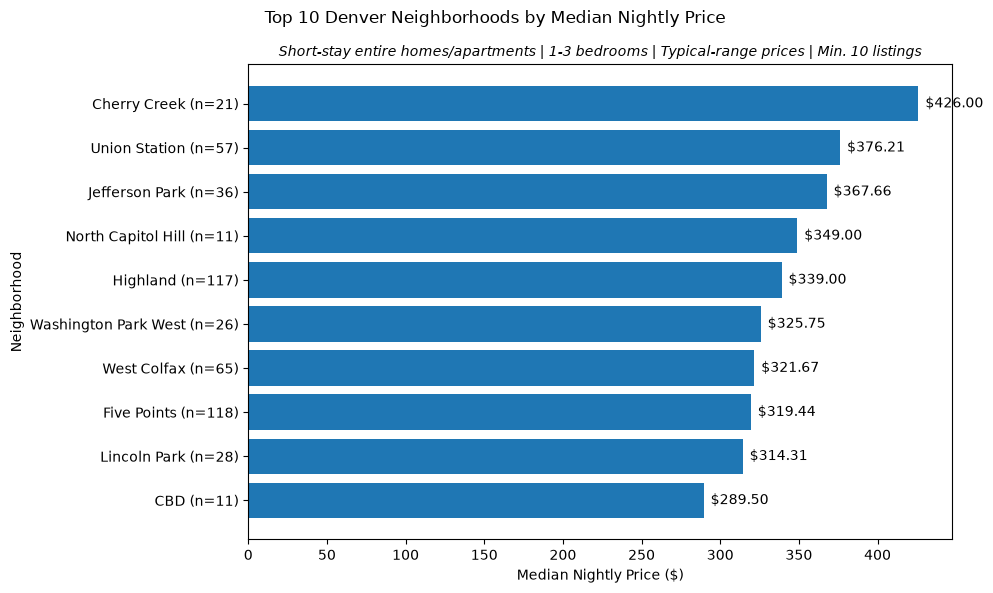

In [ ]:
neighborhood_labels = [
    f"{neighborhood} (n={count})"
    for neighborhood, count in zip(
        chart_data.index,
        chart_data["listing_count"]
    )
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    neighborhood_labels,
    chart_data["median_price"]
)

fig.suptitle("Top 10 Denver Neighborhoods by Median Nightly Price")
ax.set_title(
    "Short-stay entire homes/apartments | 1-3 bedrooms | "
    "Typical-range prices | Min. 10 listings",
    fontsize=10,
    style="italic"
)
ax.set_xlabel("Median Nightly Price ($)")
ax.set_ylabel("Neighborhood")
ax.bar_label(bars, fmt="$%.2f", padding=5)

ax.invert_yaxis()

plt.tight_layout()

fig.savefig(
    project_root / "outputs" / "charts" / "neighborhood_median_prices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Within your filtered comparable segment, Cherry Creek has the highest median nightly price among neighborhoods with at least 10 qualifying listings, at $426.
Union Station follows at $376.21, while Jefferson Park has a median of approximately $367.67.

We should also remember that the properties differ in characteristics beyond our current filters, including exact bedroom count, capacity, amenities, and property type.

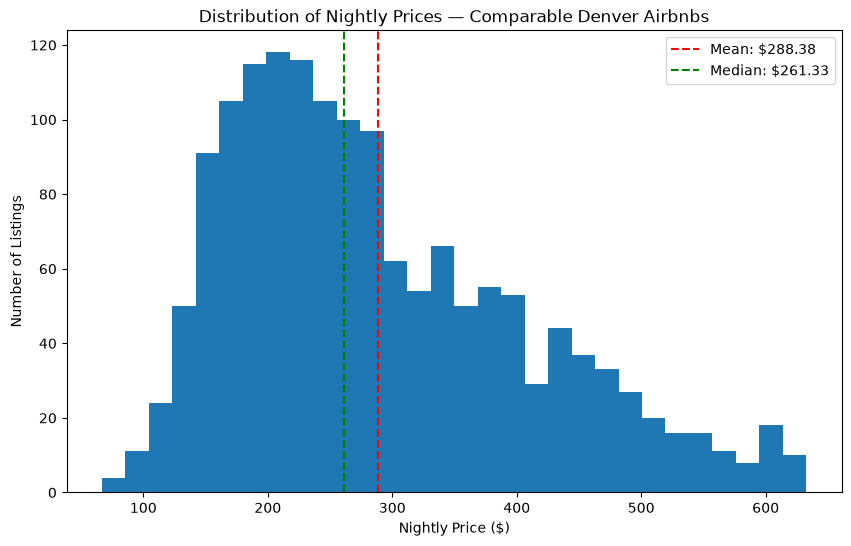

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

mean_price = comparable_df["cleaned_price"].mean()
median_price = comparable_df["cleaned_price"].median()

ax.hist(
    comparable_df["cleaned_price"],
    bins=30
)

ax.set_title("Distribution of Nightly Prices — Comparable Denver Airbnbs")
ax.set_xlabel("Nightly Price ($)")
ax.set_ylabel("Number of Listings")

ax.axvline(
    x=mean_price,
    color="red",
    linestyle="--",
    label=f"Mean: ${mean_price:,.2f}"
)

ax.axvline(
    x = median_price,
    color="green",
    linestyle="--",
    label=f"Median: ${median_price:,.2f}"
)

ax.legend()

fig.savefig(
    project_root / "outputs" / "charts" / "comparable_airbnbs_price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

A. The distribution appears right-skewed (positively skewed).
Most listings are concentrated toward the lower and middle portions of the price range, while fewer listings have substantially higher prices.
B. The highest concentration appears around $180–$250 per night.
The tallest bars occur around this range, with roughly 110–120 listings in the most populated bins.
Remember that a histogram's bars represent price intervals, not individual prices.
C. The distribution has a relatively long right tail.
Prices extend beyond $600, but the frequency of listings generally decreases as prices increase.
This suggests that the mean nightly price may be higher than the median, which we'll verify next.
D. The distribution is not perfectly symmetrical.
This matters because the mean can be pulled upward by relatively expensive listings, while the median is less sensitive to extreme values.

We can observe that:
- The highest concentration of listings occurs around $180–$250 per night.
- The distribution extends considerably farther toward expensive listings than toward inexpensive listings.
- The mean reference line appears to the right of the median reference line.

In [32]:
comparable_df["cleaned_price"].skew()

np.float64(0.7608065625355527)

In [33]:
import seaborn as sns 

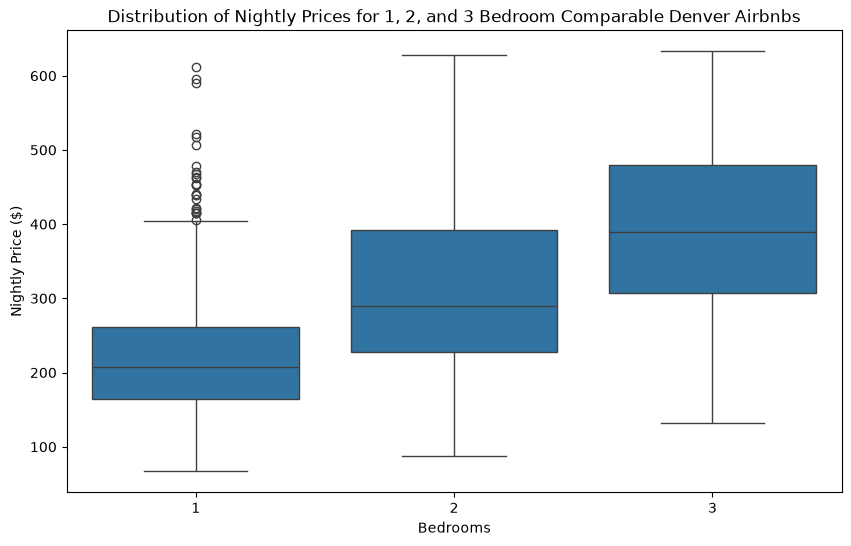

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=comparable_df,
    x="bedrooms",
    y="cleaned_price",
    ax=ax
)

ax.set_title("Distribution of Nightly Prices for 1, 2, and 3 Bedroom Comparable Denver Airbnbs")
ax.set_xlabel("Bedrooms")
ax.set_ylabel("Nightly Price ($)")

fig.savefig(
    project_root / "outputs" / "charts" / "bedroom_price_distribution_scatter_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Finding A: Median prices increase with bedroom count
Your visualization supports the expectation that larger properties generally have higher advertised nightly prices.
Three-bedroom listings have the highest median, followed by two-bedroom and one-bedroom listings.
However, this doesn't necessarily mean that three-bedroom listings offer better value or generate greater profitability.

Finding B: Price variability increases with bedroom count
The boxes for two- and three-bedroom listings are noticeably taller than the one-bedroom box.
The interquartile range measures the spread of the middle 50% of observations.
A larger IQR indicates greater absolute price variability.

Finding C: One-bedroom listings have several outliers
Your one-bedroom group contains numerous individual points above its upper whisker.
This introduces an important distinction:
These are box-plot outliers, not necessarily the same observations classified as price outliers in our SQL cleaning pipeline.

In [35]:
bedroom_summary = comparable_df.groupby("bedrooms").agg(
    listing_count=("id", "count"),
    mean_price=("cleaned_price", "mean"),
    median_price=("cleaned_price", "median"),
    min_price=("cleaned_price", "min"),
    max_price=("cleaned_price", "max"),
    std_price=("cleaned_price", "std"),
    q1=("cleaned_price", lambda x: x.quantile(0.25)),
    q3=("cleaned_price", lambda x: x.quantile(0.75))
)

bedroom_summary["iqr"] = bedroom_summary["q3"] - bedroom_summary["q1"]

bedroom_summary["cv_pct"] = bedroom_summary["std_price"] * 100 / bedroom_summary["mean_price"]

bedroom_summary.index.name = "bedrooms"
bedroom_summary.round(2)

,listing_count,mean_price,median_price,min_price,max_price,std_price,q1,q3,iqr,cv_pct
bedrooms,,,,,,,,,,
1,706,223.88,207.75,66.67,612.00,82.07,165.00,261.00,96.00,36.66
2,557,314.33,290.00,87.10,628.00,112.13,227.33,392.00,164.67,35.67
3,282,398.58,389.42,132.33,632.67,111.13,307.25,479.62,172.38,27.88


Key findings

1. Nightly prices increase with bedroom count.
The median price increases from $207.75 for one-bedroom listings to $389.42 for three-bedroom listings, an increase of approximately 87%.

2. Two-bedroom listings have the highest absolute standard deviation.
This is interesting because our earlier box plot suggested that three-bedroom listings might have the greatest variability.
However, your results show:
- 1 bedroom: $82.07
- 2 bedrooms: $112.13
- 3 bedrooms: $111.13
This illustrates why visualizations and statistical summaries should be used together. Standard deviation and IQR measure different aspects of dispersion.

3. All three bedroom groups have means above their medians.
This is consistent with positively skewed price distributions, where higher-priced listings pull the mean upward.
However, we would need additional analysis to quantify skewness.

Finding 1: Three-bedroom listings have the highest IQR
The middle 50% of three-bedroom listing prices span $172.38, compared with $96.00 for one-bedroom listings.
This aligns with the box plot you created earlier, where the three-bedroom category had the tallest box.

Finding 2: Two-bedroom listings have the highest standard deviation
Two-bedroom listings have a standard deviation of $112.13, slightly higher than three-bedroom listings at $111.13.
This demonstrates that IQR and standard deviation capture different aspects of variability. IQR measures the spread of the middle 50%, whereas standard deviation considers deviations across the entire distribution.

Finding 3: One-bedroom listings have the highest relative variability
This means one-bedroom listings have the greatest price dispersion relative to their average nightly price, even though they have the lowest absolute standard deviation.
An important distinction: a higher CV does not automatically imply greater investment risk or revenue volatility. We're measuring variation in advertised nightly prices across different listings, not changes in revenue over time.

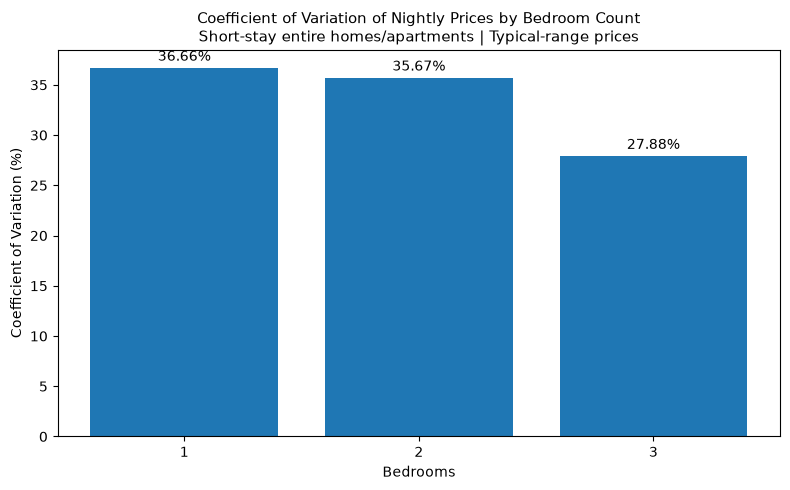

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    bedroom_summary.index,
    bedroom_summary["cv_pct"]
)

ax.set_xticks(bedroom_summary.index)
ax.set_title(
    "Coefficient of Variation of Nightly Prices by Bedroom Count\n"
    "Short-stay entire homes/apartments | Typical-range prices",
    fontsize=11
)
ax.set_xlabel("Bedrooms")
ax.set_ylabel("Coefficient of Variation (%)")

ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()

fig.savefig(
    project_root / "outputs" / "charts" / "bedroom_count_price_cv_pct.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Among comparable Denver Airbnb listings, three-bedroom properties exhibit the lowest relative variation in advertised nightly prices (27.88% CV), despite having the highest average nightly price. One-bedroom properties show the greatest relative price dispersion (36.66% CV).

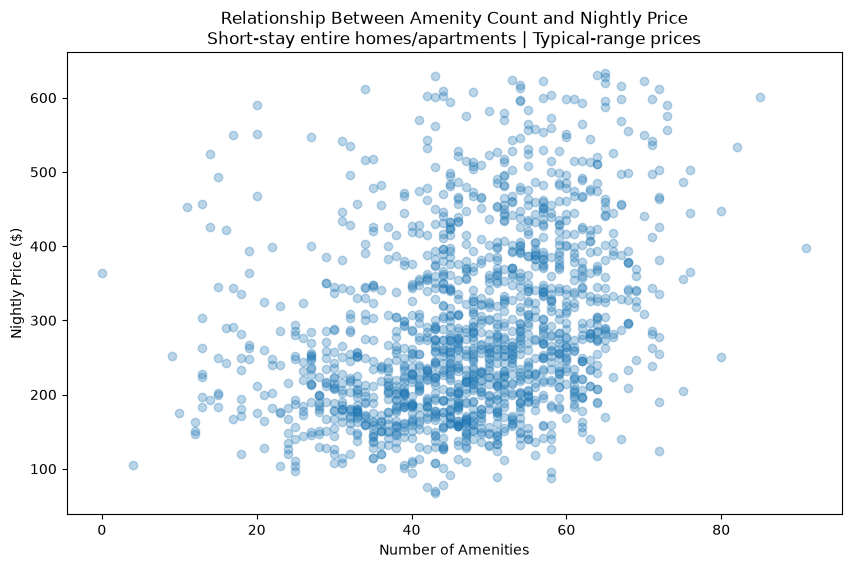

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    comparable_df["amenity_count"],
    comparable_df["cleaned_price"],
    alpha=0.3
)

ax.set_title("Relationship Between Amenity Count and Nightly Price\n"
    "Short-stay entire homes/apartments | Typical-range prices")
ax.set_xlabel("Number of Amenities")
ax.set_ylabel("Nightly Price ($)")

fig.savefig(
    project_root / "outputs" / "charts" / "amenity_price_relationship_scatter_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
comparable_df["amenity_count"].corr(
    comparable_df["cleaned_price"]
)

np.float64(0.328373157590975)

In [39]:
bedroom_correlations = comparable_df.groupby("bedrooms").apply(
    lambda group: group["amenity_count"].corr(
        group["cleaned_price"]
    )
)

bedroom_correlations

bedrooms
1    0.196755
2    0.197759
3    0.200418
dtype: float64

Positive trend: Listings with more amenities generally appear to have higher nightly prices.

Substantial dispersion: Listings with approximately 50 amenities range from under $100 to over $600 per night. Amenity count alone clearly does not explain pricing.

Concentration: Many listings cluster around 35–65 amenities and $150–$350 per night.

Finding 1: The overall relationship is stronger
Across all comparable listings, the correlation is approximately +0.33.
However, when we separate listings by bedroom count, the correlation decreases to approximately +0.20 in every group.
This suggests that bedroom count helps explain part of the overall association between amenity count and nightly price.
For example, larger properties may naturally offer more amenities while also commanding higher prices.

Finding 2: The relationship remains positive
All three bedroom categories have positive correlations.
This suggests that even among properties with the same bedroom count, listings with more amenities tend to have somewhat higher nightly prices.
However, these relationships are relatively weak.

Finding 3: The correlations are remarkably consistent
The bedroom-specific correlations range from approximately +0.197 to +0.200.
That's a very small difference.
This suggests that the linear relationship between amenity count and nightly price is similar in strength across the three bedroom categories.
Importantly, similar correlations do not necessarily mean that adding one amenity is associated with the same dollar increase in price across groups. Correlation measures standardized association, not the dollar slope.

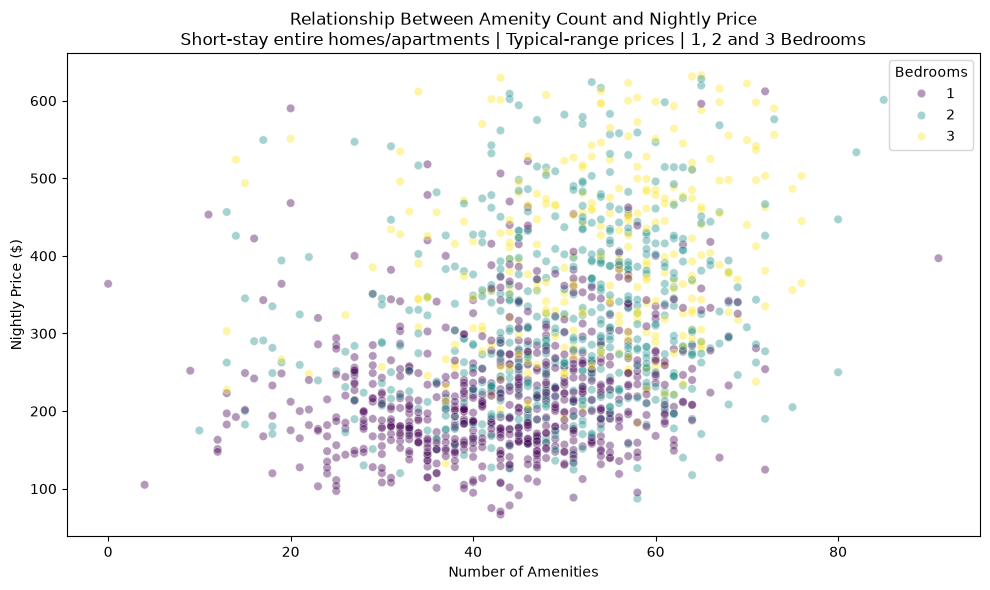

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=comparable_df,
    x="amenity_count",
    y="cleaned_price",
    hue="bedrooms",
    hue_order=[1, 2, 3],
    palette="viridis",
    alpha=0.4,
    ax=ax
)

ax.set_title("Relationship Between Amenity Count and Nightly Price\n"
    "Short-stay entire homes/apartments | Typical-range prices | 1, 2 and 3 Bedrooms")
ax.legend(title="Bedrooms")
ax.set_xlabel("Number of Amenities")
ax.set_ylabel("Nightly Price ($)")

plt.tight_layout()

fig.savefig(
    project_root / "outputs" / "charts" / "amenity_price_relationship_by_bedroom.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Finding 1: Bedroom count is strongly associated with different price levels.
The purple points (1-bedroom listings) are concentrated at lower nightly prices, while yellow points (3-bedroom listings) are generally concentrated at higher prices.

Finding 2: Amenity counts overlap substantially across bedroom categories.
Many listings across all three groups have approximately 40–65 amenities.
This indicates that amenity count alone does not reliably distinguish larger properties from smaller ones.

Finding 3: Listings with similar amenity counts can have very different prices.
For example, around 50 amenities, the chart shows properties priced anywhere from approximately $100 to over $600.
This reinforces our earlier finding that the bedroom-specific correlations are weak (approximately +0.20).
It also suggests that factors beyond amenity count, including bedroom count, location, property characteristics, and potentially listing quality, contribute to pricing differences.

Analytical conclusion: Amenity count has a positive association with nightly price, but that association is considerably weaker when comparing listings with the same bedroom count. This suggests that differences in bedroom count account for part of the overall relationship.

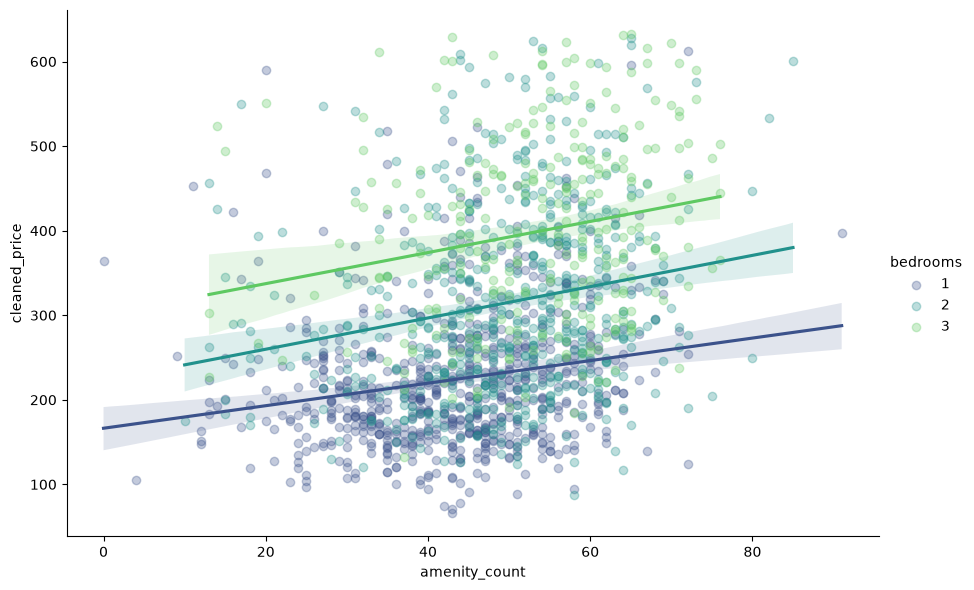

In [41]:
sns.lmplot(
    data=comparable_df,
    x="amenity_count",
    y="cleaned_price",
    hue="bedrooms",
    hue_order=[1, 2, 3],
    palette="viridis",
    height=6,
    aspect=1.5,
    scatter_kws={"alpha": 0.3}
)

1. All three regression lines have positive slopes.
This indicates that listings with more amenities tend to have higher nightly prices within each bedroom category.
However, the points are widely dispersed around the lines, consistent with the weak positive correlations we previously calculated.

2. The regression lines have relatively similar slopes.
Visually, the lines appear approximately parallel, suggesting that the dollar-price association with an additional amenity may be reasonably similar across bedroom categories.
We would need to calculate the actual regression coefficients to determine how much those slopes differ.

3. The lines are vertically separated.
This is arguably the most important finding.
At approximately 50 amenities, the fitted regression lines suggest:
Bedrooms	Estimated nightly price
1	~$240
2	~$315
3	~$395
These are approximate fitted values read from the chart, not observed listing prices.
The separation suggests that bedroom count is associated with substantial differences in nightly prices even when comparing properties with similar amenity counts.

In [42]:
from scipy.stats import linregress

for bedrooms, group in comparable_df.groupby("bedrooms"):
    result = linregress(
        group["amenity_count"],
        group["cleaned_price"]
    )

    print(f"{bedrooms} Bedrooms")
    print(f"Slope: {result.slope:.2f}")
    print(f"R-squared: {result.rvalue**2:.3f}")
    print()

1 Bedrooms
Slope: 1.33
R-squared: 0.039

2 Bedrooms
Slope: 1.85
R-squared: 0.039

3 Bedrooms
Slope: 1.84
R-squared: 0.040



For each additional amenity, the model estimates an increase in nightly price of:
- 1-bedroom listings: $1.33
- 2-bedroom listings: $1.85
- 3-bedroom listings: $1.84
For example, consider two comparable 2-bedroom listings, one with 40 amenities and another with 50.
Based on the fitted regression slope:
\[
(50-40)\times \$1.85=\$18.50
\]

The model estimates an $18.50 difference in nightly price associated with those 10 additional amenities.
However, this is an association, not a causal estimate. We cannot conclude that adding 10 amenities would actually increase a property's nightly price by $18.50.

An R² of 0.039 means that amenity count explains approximately 3.9% of the observed variation in nightly prices within that bedroom group.
The remaining 96.1% is unexplained by this particular model.
That unexplained variation could reflect neighborhood, property size, location, listing quality, specific amenities, and many other factors.
Importantly, we cannot attribute that remaining percentage to any particular variable without further analysis.

Our conclusion: Amenity count has a positive but weak linear relationship with nightly price within each bedroom category. It is not a strong standalone predictor of nightly price.
The stronger overall correlation also suggests that bedroom count contributes to the association observed when all listings are analyzed together.

In [43]:
from scipy.stats import linregress

print("SciPy is working!")

SciPy is working!


In [44]:
import scipy

print(scipy.__version__)

1.18.1


In [45]:
from scipy.stats import linregress

print("SciPy regression tools are ready!")

SciPy regression tools are ready!


Business insight — Amenity count and nightly pricing

Our exploratory analysis identified a positive but relatively weak relationship between amenity count and nightly price after segmenting comparable Denver Airbnb listings by bedroom count. Amenity count explained approximately 4% of observed price variation within each bedroom category.

Recommendation: Hosts should prioritize identifying high-value amenities rather than maximizing their total amenity count. They should also audit their listing descriptions and amenity selections to ensure existing features are accurately represented. Further analysis of individual amenities, neighborhood differences, and property characteristics is necessary before estimating potential revenue impacts.

In [46]:
host_summary = (
    comparable_df
    .groupby("host_scale")
    .agg(
        listing_count=("id", "count"),
        mean_price=("cleaned_price", "mean"),
        median_price=("cleaned_price", "median")
    )
    .sort_values("median_price", ascending=False)
    .round(2)
)

host_summary
    

,listing_count,mean_price,median_price
host_scale,,,
Large/professional operator,184,318.55,318.00
Medium operator,74,314.25,305.00
Small multi-listing host,228,297.29,275.25
Single-listing host,1059,279.41,250.50


Finding 1: Larger operators generally have higher nightly prices.
Large/professional operators have a median nightly price of $318, compared with $250.50 for single-listing hosts.
That's a difference of $67.50, or approximately 26.9%.

Finding 2: Single-listing hosts dominate the comparable market.
Of the 1,545 qualifying listings, 1,059 belong to single-listing hosts, representing approximately 68.5%.
This suggests that individual hosts represent a substantial portion of the comparable listing supply.

Finding 3: Mean prices exceed median prices across all four categories.
This suggests some degree of right-skewness within each category, particularly among smaller hosts.
However, we'd need to examine the underlying distributions to assess the extent of that skewness.

Important analytical limitation
Your results establish an association between host scale and nightly price, but they don't prove that larger operators can charge more because they're larger.
Other potential explanations include property size, neighborhood, property category, and amenities.
That distinction is important when presenting this finding to stakeholders.

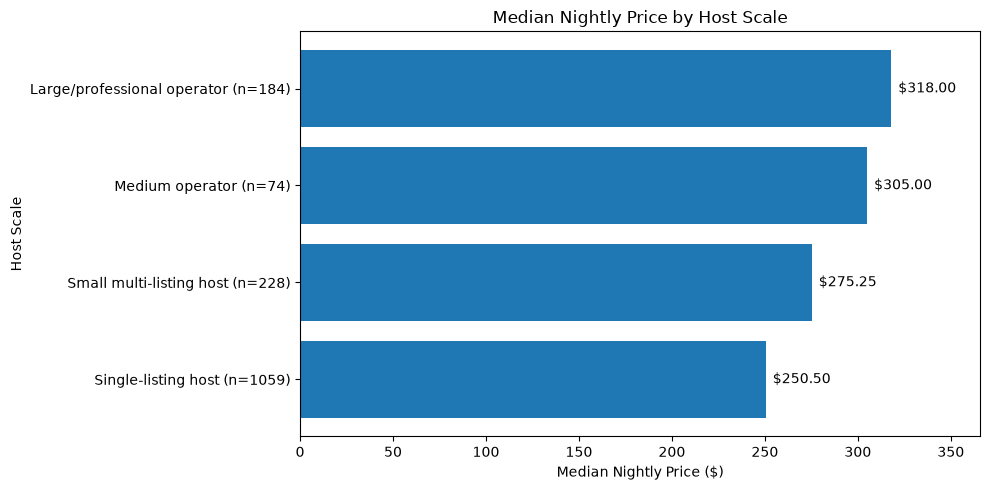

In [ ]:
host_labels = [
    f"{host} (n={count})"
    for host, count in zip(
        host_summary.index,
        host_summary["listing_count"]
    )
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    host_labels,
    host_summary["median_price"]
)

ax.set_title("Median Nightly Price by Host Scale")
ax.set_xlabel("Median Nightly Price ($)")
ax.set_ylabel("Host Scale")


ax.bar_label(bars, fmt="$%.2f", padding=5)
ax.invert_yaxis()

ax.set_xlim(0, host_summary["median_price"].max() * 1.15)

plt.tight_layout()

fig.savefig(
    project_root / "outputs" / "charts" / "median_price_by_host_scale.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
    

In [48]:
reviews_df = con.execute("""
    SELECT listing_id, review_id
    FROM cleaned_reviews
""").df()

review_summary = (
    reviews_df
    .groupby("listing_id")
    .agg(review_count=("review_id", "count"))
    .reset_index()
)

review_summary.head()
    

,listing_id,review_count
0,360,186
1,364,87
2,592,221
3,686,252
4,1940,278


In [49]:
listings_reviews_df = cleaned_listings_df.merge(
    review_summary,
    left_on="id",
    right_on="listing_id",
    how="left",
    validate="one_to_one"
)

listings_reviews_df["review_count"] = (
    listings_reviews_df["review_count"]
    .fillna(0)
    .astype(int)
)

listings_reviews_df[
    ["id", "host_scale", "cleaned_price", "review_count"]
].head()

,id,host_scale,cleaned_price,review_count
0,862994448954640130,Large/professional operator,NaN,33
1,854244360034373969,Large/professional operator,113.97,5
2,854963237650793916,Medium operator,319.00,31
3,855142734203516176,Single-listing host,642.50,34
4,855327275561281832,Single-listing host,793.60,107


In [50]:
print("Original listings:", len(cleaned_listings_df))
print("Merged listings:", len(listings_reviews_df))
print("Unique listings:", listings_reviews_df["id"].nunique())

Original listings: 4939
Merged listings: 4939
Unique listings: 4939


In [51]:
filtered_reviews_df = listings_reviews_df[
    listings_reviews_df["bedrooms"].between(1, 3)
]

host_review_pivot = pd.pivot_table(
    data=filtered_reviews_df,
    index="host_scale",
    columns="bedrooms",
    values="review_count",
    aggfunc="mean"
).round(2)

host_review_pivot

bedrooms,1,2,3
host_scale,,,
Large/professional operator,34.51,38.60,35.52
Medium operator,49.50,80.81,73.43
Single-listing host,102.96,73.13,59.45
Small multi-listing host,62.97,60.67,44.42


In [52]:
# Close the existing in-memory connection
con.close()

# Define the database file path
db_path = project_root / "data" / "denver_airbnb.duckdb"

# Connect to the persistent database
con = duckdb.connect(str(db_path))

# Register raw datasets in the persistent database
csv_files = {
    "raw_listings": "detailed_listings.csv",
    "raw_calendar": "detailed_calendar.csv",
    "raw_reviews": "detailed_reviews.csv"
}

for view_name, filename in csv_files.items():
    file_path = project_root / "data" / filename

    con.execute(
        f"CREATE OR REPLACE VIEW {view_name} AS "
        f"SELECT * FROM read_csv_auto('{file_path.as_posix()}')"
    )

# Verify the connection and raw views
con.execute("""
    SELECT
        (SELECT COUNT(*) FROM raw_listings) AS listing_count,
        (SELECT COUNT(*) FROM raw_calendar) AS calendar_count,
        (SELECT COUNT(*) FROM raw_reviews) AS review_count
""").df()

,listing_count,calendar_count,review_count
0,4939,1806385,354741


In [53]:
cleaning_sql_path = project_root / "sql" / "01_cleaning.sql"

cleaning_sql = cleaning_sql_path.read_text(encoding="utf-8")

con.execute(cleaning_sql)

In [54]:

con.execute("""
    SELECT table_name
    FROM information_schema.views
    WHERE table_name LIKE 'raw_%'
       OR table_name LIKE 'cleaned_%'
    ORDER BY table_name
""").df()
    

,table_name
0,cleaned_calendar
1,cleaned_listings
2,cleaned_reviews
3,raw_calendar
4,raw_listings
5,raw_reviews


In [55]:
con.close()

In [56]:
con = duckdb.connect(str(db_path))

In [57]:

con.execute("""
    SELECT
        (SELECT COUNT(*) FROM cleaned_listings) AS listings,
        (SELECT COUNT(*) FROM cleaned_calendar) AS calendar,
        (SELECT COUNT(*) FROM cleaned_reviews) AS reviews
""").df()
    

,listings,calendar,reviews
0,4939,1802735,354646


In [58]:
validation_summary = con.execute("""
    SELECT
        COUNT(*) AS total_listings,
        COUNT(DISTINCT id) AS unique_listings,

        COUNT(*) FILTER (
            WHERE cleaned_price IS NULL
        ) AS missing_prices,

        COUNT(*) FILTER (
            WHERE cleaned_price <= 0
        ) AS invalid_prices,

        COUNT(*) FILTER (
            WHERE neighbourhood_cleansed IS NULL
        ) AS missing_neighborhoods

    FROM cleaned_listings
""").df()

validation_summary

,total_listings,unique_listings,missing_prices,invalid_prices,missing_neighborhoods
0,4939,4939,688,0,0


In [59]:
price_validation = con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE price IS NULL
        ) AS source_price_missing,

        COUNT(*) FILTER (
            WHERE price IS NOT NULL
              AND cleaned_price IS NULL
        ) AS conversion_failed,

        COUNT(*) FILTER (
            WHERE cleaned_price IS NULL
        ) AS cleaned_price_missing

    FROM cleaned_listings
""").df()

price_validation

,source_price_missing,conversion_failed,cleaned_price_missing
0,688,0,688


We should not replace missing prices with zero or the overall median, because doing so could distort pricing distributions and neighborhood comparisons.
Instead, we'll preserve NULL values and exclude them only from analyses that require valid prices.
This is also a useful data-quality decision to document in your final portfolio.

In [60]:
# Define output directory for cleaned datasets
output_dir = project_root / "outputs" / "tables"
output_dir.mkdir(parents=True, exist_ok=True)

In [61]:
export_files = {
    "cleaned_listings": "cleaned_listings.csv",
    "cleaned_calendar": "cleaned_calendar.csv",
    "cleaned_reviews": "cleaned_reviews.csv"
}

for view_name, filename in export_files.items():
    file_path = output_dir / filename

    con.execute(
        f"""
        COPY {view_name}
        TO '{file_path.as_posix()}'
        (FORMAT CSV, HEADER TRUE)
        """
    )

    print(f"{filename}: {file_path.exists()}")

cleaned_listings.csv: True
cleaned_calendar.csv: True
cleaned_reviews.csv: True


In [62]:
print("Comparable listings:", len(comparable_df))
print("Median nightly price:", comparable_df["cleaned_price"].median())

Comparable listings: 1545
Median nightly price: 261.33
